While we used Linear Regression to predict a continuos number / value based on input features, Logistic Regression is used to predict given certain input features, the category it falls in. Hence we can use Logistic Regression for classification. 

**Lets first import all the necessary libraries**

In [606]:
import os
import numpy as np
from matplotlib import pyplot as plt
from scipy import optimize

For the data, lets predict whether a student gets accepted into a university based on their two exam performances. The first two columns of the data contain the student's first and second exam scores and the goal is to predict how likely they are to get accepted into uni.

**Load the data**

In [607]:
data = np.loadtxt(os.path.join('Data', 'data1.txt'), delimiter=',')
X, y = data[:, 0:2], data[:, 2]

Lets now visualize the data and see how the data points are spread

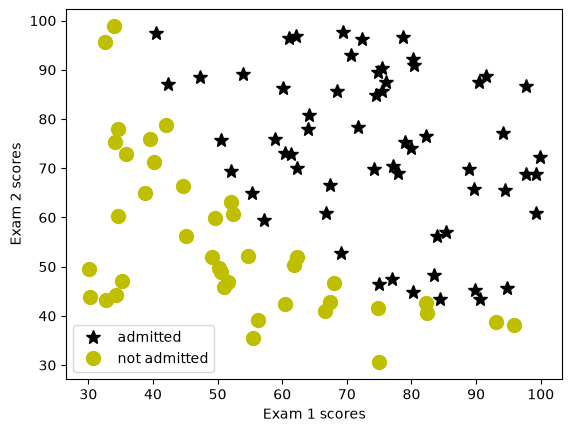

In [608]:
def plotData(X, y):
    # Filter out the positive and negative rows of data points
    pos = y == 1
    neg = y == 0

    plt.plot(X[pos, -2], X[pos, -1], 'k*', ms = '10', label='admitted')
    plt.plot(X[neg, -2], X[neg, -1], 'yo', ms = '10', label='not admitted')


plotData(X, y)
plt.xlabel('Exam 1 scores')
plt.ylabel('Exam 2 scores')
plt.legend()

First implement the sigmoid function defined by:-

$$g(z) = \frac{1}{1+e^{-z}}$$

Where z = $$\theta^T.x   /   wx + b$$ 

This is the primary function used to omit values between 0 and 1, giving a probability of how likely it is to fall into a certain category. However, if the output of the function g(z) is greater than 0.5, it is considered as 1 and less is considered 0 in this project.

In [609]:
def sigmoid(z):
    z = np.array(z)

    g = 1 / (1 + np.exp(-z))

    return g

sigmoid(0)

np.float64(0.5)

Set the variables m and n to the shape of X

In [610]:
m, n = X.shape

# Add the bias term to X
X = np.concatenate([np.ones((m, 1)), X], axis=1)

The cost function in logistic regression is defined by:-

$$ J(\theta) = \frac{1}{m} \sum_{i=1}^{m} \left[ -y^{(i)} \log\left(h_\theta\left( x^{(i)} \right) \right) - \left( 1 - y^{(i)}\right) \log \left( 1 - h_\theta\left( x^{(i)} \right) \right) \right]$$

Similarly, the gradients of each feature can be calculated by using:-

$$ \frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} \sum_{i=1}^m \left( h_\theta \left( x^{(i)} \right) - y^{(i)} \right) x_j^{(i)} $$

Implementing this to code

In [611]:
def costandgrad(theta, X, y):
    J = 0
    grad = np.zeros(theta.shape)

    for i in range(m):
        z = np.dot(theta, X[i])
        pred = sigmoid(z)
        J += ((-y[i] * np.log(pred)) - ((1 - y[i]) * np.log(1 - pred)))
        err = pred - y[i]
        for j in range(theta.shape[0]):
            grad[j] += err * X[i][j]

    J /= m
    grad /= m

    return J, grad

Lets call the function with test values for theta

In [612]:
test_theta = np.zeros(n+1)

cost, grad = costandgrad(test_theta, X, y)

print(f'When theta is zero:- \n\tCost:- {cost:.3f}')
print('\tGradient:- [{:.3f}, {:.3f}, {:.4f}]'.format(*grad))


test_theta = np.array([-24, 0.2, 0.2])

cost, grad = costandgrad(test_theta, X, y)

print(f'\nTest values of theta:- \n\tCost:- {cost:.3f}')
print('\tGradient:- [{:.3f}, {:.3f}, {:.4f}]'.format(*grad))


When theta is zero:- 
	Cost:- 0.693
	Gradient:- [-0.100, -12.009, -11.2628]

Test values of theta:- 
	Cost:- 0.218
	Gradient:- [0.043, 2.566, 2.6468]


Now instead of manually implementing gradient descent to find the most optimal weights, I will be using the scipy library. Specifically the scipy.optimize module's minimize method which helps find the best optimal parameters $\theta$. [Here is the documentation](https://docs.scipy.org/doc/scipy/reference/optimize.html) 

In [613]:
option = {'maxiter': 400}
op = optimize.minimize(costandgrad,
                       test_theta,
                       (X, y),
                       jac=True,
                       method='TNC',
                       options=option)

cost = op.fun

theta = op.x

print(f'Optimal cost found by optimize.minimize: {cost:.3f}\n')

print(f'Theta: \n\t{theta}\n')

Optimal cost found by optimize.minimize: 0.203

Theta: 
	[-25.16113955   0.20623013   0.20147006]



/var/folders/jg/2fv2td996ylc1xpbgl5k5q3r0000gn/T/ipykernel_39092/736061257.py:2: OptimizeWarning: Unknown solver options: maxiter
  op = optimize.minimize(costandgrad,


Lets now plot the decision boundry using our newly found weights (the function below is out sourced and not mine)

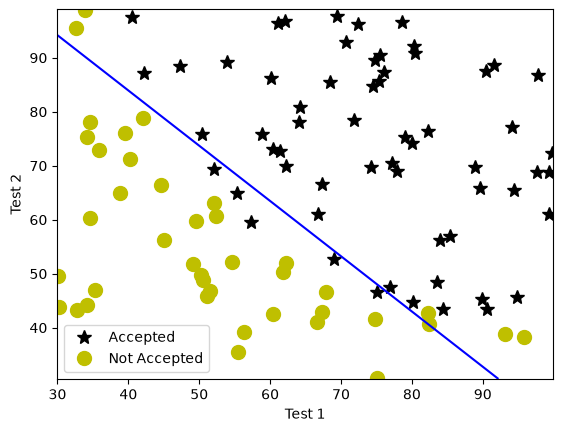

In [614]:
def plotBoundary(X, y, theta):
    """
    X     : raw data, shape (m, 2), no ones column
    y     : labels (0/1), shape (m,)
    theta : trained weights from minimize (res.x)
    """
    # 1. scatter the raw points
    plt.plot(X[y == 1, 0], X[y == 1, 1], 'k*', ms=10, label='Accepted')
    plt.plot(X[y == 0, 0], X[y == 0, 1], 'yo', ms=10, label='Not Accepted')

    # 2. build a grid covering the data
    u = np.linspace(X[:, 0].min() - 0.1, X[:, 0].max() + 0.1, 100)
    v = np.linspace(X[:, 1].min() - 0.1, X[:, 1].max() + 0.1, 100)
    U, V = np.meshgrid(u, v)

    # 3. recover the polynomial degree from the number of weights
    degree = int((-3 + np.sqrt(1 + 8 * theta.size)) / 2)

    # 4. compute z = features @ theta at every grid point
    z = expandFeatures(U.ravel(), V.ravel(), degree) @ theta
    z = z.reshape(U.shape)

    # 5. draw the curve where z = 0 (the decision boundary)
    plt.contour(U, V, z, levels=[0], colors='b')

    plt.xlabel('Test 1')
    plt.ylabel('Test 2')
    plt.legend()

plotBoundary(X[:, 1:], y, theta)
plt.show()

We can see that the decision boundary does a decent job of splitting the two categories of data points.

Lets now predict on our trianing set

In [615]:
def predict(theta, X):
    m = X.shape[0]
    p = np.zeros(m)

    for i in range(m):
        p[i] = 1 if (np.dot(theta, X[i]) >= 0.5) else 0

    return p


Lets check the probability of a student with 45 marks in exam 1 and 85 in exam 2

In [616]:
prob = sigmoid(np.dot([1, 45, 85], theta))
print(f"For a student with 45 marks on exam 1 and 85 on exam 2, the probability that he will get admitted is: {prob*100:.2f}%")

For a student with 45 marks on exam 1 and 85 on exam 2, the probability that he will get admitted is: 77.63%


Lets now predict on our training set

In [617]:
p = predict(theta, X)
print(f"Training accuracy: {np.mean(p == y) * 100:.2f}%")

Training accuracy: 89.00%


**For the next dataset, we will be predicting whether or not a microchip gets accepted or rejected based on it's two test results.**

Loading the dataset

In [618]:
data2 = np.loadtxt(os.path.join('Data', 'data2.txt'), delimiter=',')
X, y = data2[:, 0:2], data2[:, 2]
X.shape

(118, 2)

Lets now plot and see how the data points are spread

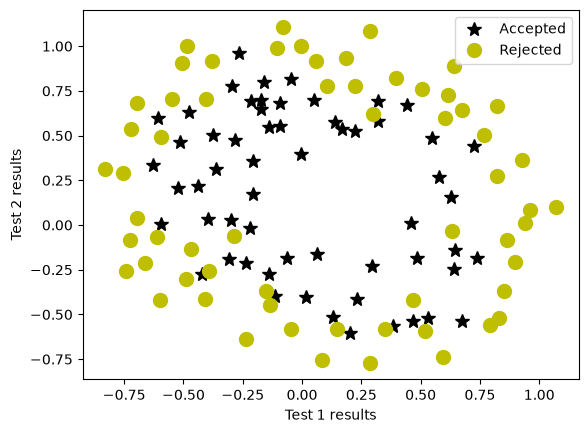

In [619]:
plotData(X, y)
plt.xlabel('Test 1 results')
plt.ylabel('Test 2 results')
plt.legend(['Accepted', 'Rejected'])
plt.show()

We can see that this data is spread differently than the first dataset and a straight linear line cannot be fit into this dataset. Hence, inorder to fit a decision boundary into this non linear dataset we need to introduce higher order polynomials into our model. This also causes high risk of overfitting so we will be using regularization in order to prevent that.

In [620]:
def expandFeatures(X1, X2, degree = 6):
    # Returns a matrix of size mx28 for degree 6 which we will be using as a default
    # add a vector of ones with same rows as X
    if X1.ndim > 0:
        out = [np.ones(X1.shape[0])]
    else:
        out = [np.ones(1)]

    # The polynomial formula to expand the features into the respective degree
    for i in range(1, degree + 1):
        for j in range(i + 1):
            out.append((X1 ** (i - j)) * (X2 ** j))

    # Finally turn each vector in the out list into columns (stack vertically)
    if X1.ndim > 0:
        return np.stack(out, axis=1)
    else:
        return np.hstack(out)

In [621]:
X = expandFeatures(X[:, 0], X[:, 1])
X.shape

(118, 28)

We can see the columns expanded from 2 to 28 and a logistic regression classifier trained on this higher-dimension feature vector will have a more complex decision boundary and will appear nonlinear when drawn in our 2-dimensional plot.

Now, since we used a higher dimensional polynomial model, there is high risk of overfitting or underfitting and so I will be applying a regularized version of logistic regression. In order to do so, we add a regularization term (penalty term) to our cost function and so the regularized cost function becomes:-


$$ J(\theta) = \frac{1}{m} \sum_{i=1}^m \left[ -y^{(i)}\log \left( h_\theta \left(x^{(i)} \right) \right) - \left( 1 - y^{(i)} \right) \log \left( 1 - h_\theta \left( x^{(i)} \right) \right) \right] + \frac{\lambda}{2m} \sum_{j=1}^n \theta_j^2 $$

The gradient for each feature also becomes:-

$$ \frac{\partial J(\theta)}{\partial \theta_0} = \frac{1}{m} \sum_{i=1}^m \left( h_\theta \left(x^{(i)}\right) - y^{(i)} \right) x_j^{(i)} \qquad \text{for } j =0 $$

$$ \frac{\partial J(\theta)}{\partial \theta_j} = \left( \frac{1}{m} \sum_{i=1}^m \left( h_\theta \left(x^{(i)}\right) - y^{(i)} \right) x_j^{(i)} \right) + \frac{\lambda}{m}\theta_j \qquad \text{for } j \ge 1 $$

The regularized term is not added for when j=0 because we dont want to regularize our bias term. Implementing to this to code:

In [622]:
def regcostandgradient(theta, X, y, lambda_):
    m = y.size
    J = 0
    grad = np.zeros(theta.shape)

    for i in range(m):
        z = np.dot(theta, X[i])
        pred = sigmoid(z)
        J += ((-y[i] * np.log(pred)) - ((1 - y[i]) * np.log(1 - pred)))
        err = pred - y[i]
        for j in range(theta.shape[0]):
            grad[j] += err * X[i][j]

    grad /= m
    grad[1:] += (lambda_ * theta[1:]) / m


    J /= m
    J += (lambda_ / (2 * m)) * np.sum(theta[1:] ** 2)

    return J, grad

lets try it with initial test values of theta

In [623]:
initial_theta = np.zeros(X.shape[1])

lambda_ = 1

cost, grad = regcostandgradient(initial_theta, X, y, lambda_)

print(f"With initial values of theta as zeors:\n\tCost: {cost:.3f}\n\tgradient(first 4): {grad[:4]}")

# Again try with initial values of ones

initial_theta2 = np.ones(X.shape[1])

lambda_2 = 10

cost, grad = regcostandgradient(initial_theta2, X, y, lambda_2)

print(f"\n\n With initial values of theta as ones:\n\tCost: {cost:.3f}\n\tgradient(first 4): {grad[:4]}")

With initial values of theta as zeors:
	Cost: 0.693
	gradient(first 4): [8.47457627e-03 1.87880932e-02 7.77711864e-05 5.03446395e-02]


 With initial values of theta as ones:
	Cost: 3.165
	gradient(first 4): [0.34604507 0.16135192 0.19479576 0.22686278]


Now, again lets find the best and most optimal values of theta using scipy.optimize library as we did above

/var/folders/jg/2fv2td996ylc1xpbgl5k5q3r0000gn/T/ipykernel_39092/3727539554.py:3: OptimizeWarning: Unknown solver options: maxiter
  opt = optimize.minimize(regcostandgradient,


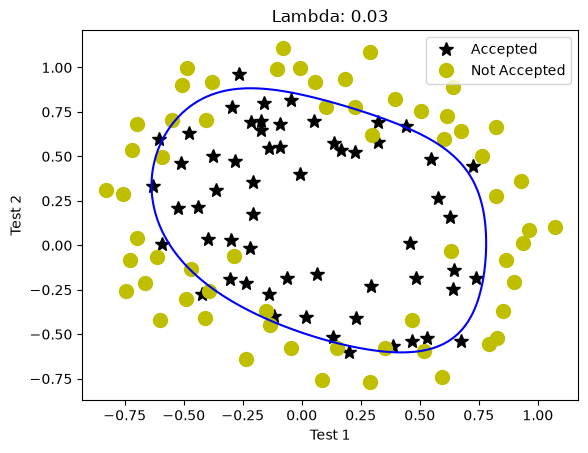

Training accuracy: 84.75


In [624]:
options= {'maxiter': 100}
lambda_ = 0.03
opt = optimize.minimize(regcostandgradient,
                        initial_theta,
                        (X, y, lambda_),
                        jac=True,
                        method='TNC',
                        options=options)

cost = opt.fun

theta = opt.x

plotBoundary(X[:, 1:], y, theta)
plt.title(f"Lambda: {lambda_}")
plt.show()

# Predict on training set with newly found optimal values of theta
p = predict(theta, X)

print(f"Training accuracy: {np.mean(p == y) * 100:.2f}")

The training accuracy vaires with different values of lambda but achieving roughly 85% accuracy on the training set is pretty good on a logistic regression model.